# Churn ClientCo – 1. Modèle mensuel

Modèle dont les résultats sont repris dans la présentation.

- Photos le 1er de chaque mois, d'octobre 2023 à mars 2024 : 28 features calculées avant la date, cibles observées après.
- Cibles : départ total (aucun achat pendant 3 × le rythme habituel, entre 90 et 180 jours) ou forte baisse (CA du trimestre < 50 % de la référence).
- Clients : 80 % apprentissage (photos d'octobre à janvier), 20 % test (photo du 1er mars 2024).
- Modèles : règle simple, régression logistique, XGBoost.
- Liste d'appels : clients classés par probabilité × CA, limitée à la capacité des commerciaux.

Définitions détaillées des features : `DESCRIPTION_VARIABLES` dans `churn_commun.py`.
Résultats : `modele_churn/resultats/mensuel/resultats.json`.

In [14]:
# Se place à la racine du dépôt (dossier contenant data/)
import os, sys, json
import pandas as pd
from IPython.display import Image, display
if os.path.basename(os.getcwd()) == "modele_churn":
    os.chdir("..")
sys.path.insert(0, os.path.abspath("modele_churn"))
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
RES = os.path.join("modele_churn", "resultats")
print("Dossier de travail :", os.path.basename(os.getcwd()))

Dossier de travail : case_BCGX


## Paramètres
`CONTACTS_PAR_MOIS` : contacts par commercial et par mois (hypothèse : 2 visites + 18 appels).

In [15]:
CONTACTS_PAR_MOIS = 20
PART_CLIENTS_TEST = 0.20

## Lancement
Le premier lancement lit le dataset, les suivants utilisent le cache.

In [16]:
import importlib, churn_1_modele_mensuel as script
importlib.reload(script)
sys.argv = ["churn_1_modele_mensuel"] + ["--contacts-par-mois", str(CONTACTS_PAR_MOIS), "--part-clients-test", str(PART_CLIENTS_TEST)]
script.main()

Cache trouvé : modele_churn\cache\agregats.pkl

== Représentativité ==
  periode_debut: 2022-09-22
  periode_fin: 2024-09-22
  lignes: 63319315
  doublons: 1488779
  lignes_neg: 2334447
  ca_retours_meur: 567.3
  lignes_nulles: 2283659
  produits: 607418
  clients: 170589
  agences: 582
  ca_dataset_12m_meur: 4685.0
  part_ca_groupe: 0.302
  ca_dataset_2023_meur: 4532.0
  part_ca_groupe_2023: 0.292
  facteur_groupe: 3.42
  part_agences: 0.582
  clients_actifs_12m: 142228
  part_clients: 0.316

Photos : ['2023-10', '2023-11', '2023-12', '2024-01', '2024-02', '2024-03'] | apprentissage <= 2024-01, test = 2024-03
  churn_total    | Règle métier (silence vs rythme habituel)  | AUC 0.602 | précision 0.09 | CA à risque capté 0.325
  churn_total    | Régression logistique                      | AUC 0.833 | précision 0.198 | CA à risque capté 0.453
  churn_total    | Gradient boosting (XGBoost)                | AUC 0.844 | précision 0.275 | CA à risque capté 0.505
  churn_partiel  | Règle méti

## Résultats
### Représentativité et capacité

In [17]:
R = json.load(open(os.path.join(RES, "mensuel", "resultats.json"), encoding="utf-8"))
display(pd.Series(R["dataset"], name="dataset").to_frame())
display(pd.Series(R["capacite"], name="capacité").to_frame())

,dataset
periode_debut,2022-09-22
periode_fin,2024-09-22
lignes,63319315
doublons,1488779
lignes_neg,2334447
ca_retours_meur,567.3
lignes_nulles,2283659
produits,607418
clients,170589
agences,582


,capacité
reps_groupe,200.000
part_groupe,0.292
reps_dataset,58.400
contacts_par_mois,20.000
liste_mensuelle,1168.000
liste_trimestre,3504.000
liste_trimestre_test,702.000
part_clients_test,0.200
contacts_an_groupe,48000.000
n_clients_test,18055.000


### Churn observé au 1er mars 2024 (tous les clients réguliers)

In [18]:
display(pd.DataFrame(R["churn_descriptif"]).T)
display(pd.Series(R["silence_vs_rythme"], name="part des clients selon silence / rythme habituel").to_frame())

,pct_clients,nb_clients,ca_ref_moyen_trim_keur,perte_trim_meur,part_ca_ref,ca_risque_an_groupe_meur
churn_total,0.144,13072.0,2.1,26.76,0.027,367.0
churn_partiel,0.157,14177.0,9.6,104.24,0.104,1428.0
churn,0.301,27249.0,6.0,131.00,0.131,1795.0


,part des clients selon silence / rythme habituel
< 1x,0.425
1-2x,0.263
2-3x,0.123
3-5x,0.098
> 5x,0.090


### Performance sur les clients de test
`perte_captee_k` : part du CA à risque captée par la liste (indicateur principal) · `precision_k` : part des clients appelés qui partent · `rappel_k_gros` : part des gros clients partants présents dans la liste.

In [19]:
lignes = []
for cible, d in R["metriques"].items():
    for modele, m in d.items():
        lignes.append(dict(cible=cible, modele=modele, **{k: v for k, v in m.items() if k not in ("confusion", "perte_captee_k_meur")}))
display(pd.DataFrame(lignes).set_index(["cible", "modele"]))
print("Modèle retenu :", R["modele_retenu"])
print("Intervalle de confiance à 90 % du CA à risque capté :", R["intervalle_90_perte_captee"])

auc  pr_auc   brier  taux_base  precision_k  rappel_k  perte_captee_k  rappel_k_gros
cible         modele                                                                                                                           
churn_total   Règle métier (silence vs rythme habituel)  0.602   0.230  0.1368      0.144        0.090     0.024           0.325          0.562
              Régression logistique                      0.833   0.398  0.1835      0.144        0.198     0.053           0.453          0.808
              Gradient boosting (XGBoost)                0.844   0.422  0.0987      0.144        0.275     0.074           0.505          0.849
churn_partiel Règle métier (silence vs rythme habituel)  0.526   0.175  0.1501      0.155        0.209     0.053           0.347          0.224
              Régression logistique                      0.772   0.323  0.2016      0.155        0.189     0.048           0.398          0.229
              Gradient boosting (XGBoost)                0.793   0.371  0.1123      0.155        0.332     0.083           0.466          0.401
churn         Règle métier (silence vs rythme habituel)  0.576   0.396  0.2853      0.299        0.299     0.039           0.343          0.261
              Régression logistique                      0.757   0.547  0.1983      0.299        0.295     0.038           0.397          0.317
              Gradient boosting (XGBoost)                0.771   0.569  0.1701      0.299        0.436     0.057           0.440          0.451

Modèle retenu : Gradient boosting (XGBoost)
Intervalle de confiance à 90 % du CA à risque capté : [0.404, 0.479]


### Matrice de confusion de la liste d'appels

In [20]:
c = R["metriques"]["churn"][R["modele_retenu"]]["confusion"]
display(pd.DataFrame([[c["vrais_positifs"], c["faux_positifs"]], [c["departs_manques"], c["vrais_negatifs"]]],
                     index=["Dans la liste", "Hors liste"], columns=["Partent vraiment", "Restent"]))

,Partent vraiment,Restent
Dans la liste,306,396
Hors liste,5096,12257


### Courbe de gain et calibration

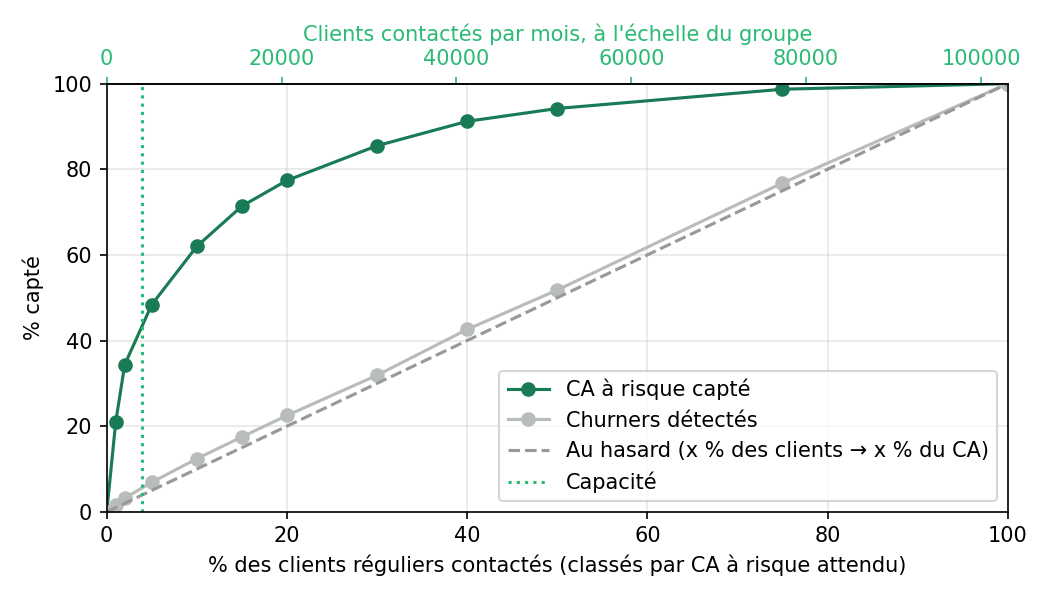

,bin,proba_predite,taux_observe,n
0,0,0.027,0.018,1806
1,1,0.073,0.065,1805
2,2,0.131,0.128,1806
3,3,0.190,0.193,1805
4,4,0.250,0.265,1806
5,5,0.312,0.328,1805
6,6,0.373,0.364,1805
7,7,0.439,0.431,1806
8,8,0.518,0.528,1805
9,9,0.652,0.672,1806


In [21]:
display(Image(os.path.join(RES, "mensuel", "courbe_gain.png")))
if "calibration" in R:
    display(pd.DataFrame(R["calibration"]))

### Valeur et features les plus utiles

In [22]:
display(pd.Series(R["lecture"], name="lecture").to_frame())
display(pd.Series(R["valeur"], name="valeur (M€ / an, groupe)").to_frame())
display(pd.Series(R.get("importance_variables", {}), name="importance (permutation, PR-AUC)").to_frame())

,lecture
sur_100_signales_partent,44.000
sur_10_churners_detectes,0.600
part_perte_captee,0.440
rappel_gros_clients,0.451
part_total_dans_liste,0.203
part_partiel_dans_liste,0.797
departs_atteints_an_groupe,20928.000


,"valeur (M€ / an, groupe)"
ca_a_risque_an_groupe_meur,1746.000
ca_a_risque_an_pct_ca,0.113
ca_a_risque_dans_liste_an_groupe_meur,769.000
marge_max_meur,189.900
marge_potentiel_theorique_meur,431.300
marge_recup_10_meur,19.000
marge_recup_25_meur,47.500
marge_recup_50_meur,94.900
marge_max_10contacts_meur,146.000
marge_max_20contacts_meur,189.900


,"importance (permutation, PR-AUC)"
indice_saison,0.0782
ca_1m,0.0213
ca_meme_trim_n1,0.0124
jours_3m,0.0119
jours_1m,0.0110
jours_12m,0.0101
tendance_6m,0.0081
recence_j,0.0080
recence_ratio,0.0072
tendance_3m,0.0061


### Exemple de liste mensuelle

In [23]:
display(pd.read_csv(os.path.join(RES, "mensuel", "liste_appels_exemple.csv"), sep=";").head(20))

,client_id,score,ca_ref_trim,ca_12m,perte_attendue,recence_j,delai_median,tendance_3m,parti_en_realite,action
0,1552980,0.130874,1501817.000,5335224.50,196549.530,2.0,1.0,7.242962e-01,0,Visite
1,1695103,0.935446,199951.780,432942.47,187044.190,59.0,4.0,5.488857e-01,1,Visite
2,988682,0.863614,191306.980,433451.66,165215.360,22.0,3.0,3.164607e+00,1,Visite
3,1621313,0.988152,136615.170,526921.70,134996.550,67.0,1.0,1.282323e-01,1,Visite
4,1744230,0.763884,162011.110,478021.28,123757.695,2.0,1.0,3.862167e-01,1,Visite
5,977478,0.775015,144488.310,496481.75,111980.580,4.0,1.0,8.742573e-02,1,Visite
6,417576,0.030065,3299401.000,13386365.00,99197.980,2.0,1.0,8.761396e-01,0,Visite
7,334549,0.776254,118976.490,208870.12,92355.940,10.0,5.0,1.365157e+00,1,Visite
8,992720,0.278594,318992.060,950777.70,88869.320,2.0,1.0,1.129536e+00,0,Visite
9,1947481,0.946092,92290.375,210707.03,87315.195,85.0,2.0,1.737952e-01,1,Visite


## Test : d'autres façons de classer la liste

Deux questions :
1. **Formule.** La liste est classée par `risque × CA`. Un très gros client avec un risque moyen peut passer devant des clients plus sûrs de partir. On teste `risque² × √CA`, qui donne plus de poids au risque.
2. **Fenêtre du CA.** Le risque porte sur les 3 mois qui suivent. Le CA utilisé dans la liste, `ca_ref_trim`, est déjà un CA trimestriel : la moyenne du même trimestre N-1 et du trimestre moyen des 12 derniers mois. La colonne `ca_12m` du tableau précédent n'est qu'une information. On compare quand même avec d'autres CA, tous ramenés à un trimestre.

Le CA réellement perdu (`perte_trim`) sert de vérité pour tous les classements, ce qui permet de les comparer.

In [24]:
import pickle, numpy as np
with open(os.path.join("modele_churn", "cache", "photos_mensuelles.pkl"), "rb") as f:
    P = pickle.load(f)
t = P["test"].reset_index(drop=True)
K = P["K_trim"] // 3                                       # liste mensuelle sur les clients de test
perte = pd.Series(np.where(t["churn"] == 1, t["perte_trim"], 0.0))
gros = t["ca_ref_trim"] >= t["ca_ref_trim"].quantile(0.8)  # 20 % plus gros clients
print(f"{len(t)} clients de test, liste mensuelle de {K} clients")

18055 clients de test, liste mensuelle de 234 clients


### 1. Le top 20 actuel, reclassé avec `risque² × √CA`

Reclasser à l'intérieur de la liste ne change que l'ordre : les 20 clients restent appelés. La vraie question, traitée au point 2, est de savoir quels clients entrent dans la liste.

In [25]:
top = t.nlargest(20, "perte_attendue").copy()
top["rang_actuel"] = range(1, len(top) + 1)
top["risque2_racine_ca"] = top["score"] ** 2 * np.sqrt(top["ca_ref_trim"].clip(lower=0))
top["rang_test"] = top["risque2_racine_ca"].rank(ascending=False, method="first").astype(int)
top["silence_vs_rythme"] = top["recence_j"] / top["delai_median"]
display(top.sort_values("rang_test")[["rang_test", "rang_actuel", "client_id", "score", "ca_ref_trim", "ca_12m", "recence_j",
                                       "delai_median", "silence_vs_rythme", "tendance_3m", "churn_total", "churn_partiel"]].round(2))

,rang_test,rang_actuel,client_id,score,ca_ref_trim,ca_12m,recence_j,delai_median,silence_vs_rythme,tendance_3m,churn_total,churn_partiel
13440,1,2,1695103,0.94,1.999518e+05,4.329425e+05,59.0,4.0,14.75,0.55,0,1
12865,2,4,1621313,0.99,1.366152e+05,5.269217e+05,67.0,1.0,67.00,0.13,1,0
7906,3,3,988682,0.86,1.913070e+05,4.334516e+05,22.0,3.0,7.33,3.16,1,0
15476,4,10,1947481,0.95,9.229038e+04,2.107070e+05,85.0,2.0,42.50,0.17,1,0
15320,5,17,1927464,0.98,7.227983e+04,2.484784e+05,61.0,1.0,61.00,0.11,1,0
13815,6,5,1744230,0.76,1.620111e+05,4.780213e+05,2.0,1.0,2.00,0.39,0,1
5044,7,13,625414,0.88,9.304548e+04,2.251299e+05,29.0,1.0,29.00,10.00,0,1
8944,8,11,1120901,0.87,9.521198e+04,1.840908e+05,19.0,5.0,3.80,0.00,0,1
7822,9,6,977478,0.78,1.444883e+05,4.964818e+05,4.0,1.0,4.00,0.09,0,1
2699,10,8,334549,0.78,1.189765e+05,2.088701e+05,10.0,5.0,2.00,1.37,0,1


### 2. Sur toute la liste : formule × fenêtre de CA

Pour chaque classement, on prend les `K` premiers clients et on mesure ce que la liste capte réellement.

In [26]:
CA = {"référence trimestrielle (actuel)": t["ca_ref_trim"],
      "3 derniers mois": t["ca_3m"],
      "6 derniers mois / 2": t["ca_6m"] / 2,
      "12 derniers mois / 4": t["ca_12m"] / 4}

def mesurer(critere):
    l = critere.nlargest(K).index
    y = t["churn"]
    return {"appelés qui partent": y[l].mean(),
            "CA à risque capté": perte[l].sum() / perte.sum(),
            "gros clients partants repérés": (y[l] & gros[l]).sum() / (y & gros).sum(),
            "CA de réf. médian (k€/trim.)": t.loc[l, "ca_ref_trim"].median() / 1e3,
            "silence médian (j)": t.loc[l, "recence_j"].median(),
            "part de départs totaux": t.loc[l, "churn_total"].sum() / max(y[l].sum(), 1)}

lignes = {("risque seul", "–"): mesurer(t["score"])}
for nom_ca, ca in CA.items():
    ca = ca.clip(lower=0)
    lignes[("risque × CA", nom_ca)] = mesurer(t["score"] * ca)
    lignes[("risque² × √CA", nom_ca)] = mesurer(t["score"] ** 2 * np.sqrt(ca))
comparaison = pd.DataFrame(lignes).T
comparaison.index.names = ["formule", "CA utilisé"]
comparaison.to_csv(os.path.join(RES, "mensuel", "test_classements.csv"), sep=";")
affiche = comparaison.copy()
for col in ["appelés qui partent", "CA à risque capté", "gros clients partants repérés", "part de départs totaux"]:
    affiche[col] = (100 * affiche[col]).round(1).astype(str) + " %"
affiche["CA de réf. médian (k€/trim.)"] = affiche["CA de réf. médian (k€/trim.)"].round(1)
affiche["silence médian (j)"] = affiche["silence médian (j)"].round(0)
display(affiche)

,,appelés qui partent,CA à risque capté,gros clients partants repérés,CA de réf. médian (k€/trim.),silence médian (j),part de départs totaux
formule,CA utilisé,,,,,,
risque seul,–,78.6 %,14.4 %,14.2 %,10.4,60.0,49.5 %
risque × CA,référence trimestrielle (actuel),47.0 %,26.9 %,16.8 %,73.8,4.0,19.1 %
risque² × √CA,référence trimestrielle (actuel),74.4 %,20.1 %,23.2 %,21.5,30.0,33.9 %
risque × CA,3 derniers mois,25.2 %,17.2 %,8.4 %,88.6,4.0,16.9 %
risque² × √CA,3 derniers mois,65.0 %,17.2 %,16.5 %,21.1,29.0,33.6 %
risque × CA,6 derniers mois / 2,34.6 %,21.6 %,11.6 %,83.7,3.0,27.2 %
risque² × √CA,6 derniers mois / 2,67.5 %,17.9 %,17.9 %,23.1,34.0,38.6 %
risque × CA,12 derniers mois / 4,42.7 %,25.7 %,15.1 %,81.1,4.0,22.0 %
risque² × √CA,12 derniers mois / 4,73.1 %,20.3 %,22.5 %,23.2,36.0,36.3 %


**Lecture.** Le meilleur classement est celui qui capte le plus de CA à risque avec le même nombre d'appels. `risque² × √CA` augmente en général la part d'appelés qui partent vraiment, mais vise des clients plus petits : il faut regarder si le CA capté baisse.